# T34 -- Phase 3: screening-signal normalization on real data

**Formula used (exact, per `iste.phase3_screening`):**

```text
screening_score(candidate) = candidate.support_score / reference_value(candidate.t_s)
```

`reference_value(t)` is T29's OWN per-timestamp percentile-95 reference (`iste.
phase3_normalization.normalize_support_grid`, reused, not reimplemented). This is a
thin, provenance-preserving adapter over T29 -- NOT a second, independent
normalization of the T16 Support signal. See `progress.md`'s T34 design specification
for the full reasoning (in particular: T36 must treat `screening_score` and T29's
normalized KDE as ONE evidence axis, not two).

In [1]:
import os, sys, time
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), os.pardir))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import json
import numpy as np
import matplotlib.pyplot as plt

from iste.ensemble_run import EnsembleRunRecords
from iste.analysis_grid import generate_analysis_grid
from iste.candidate_extraction import CandidateExtractionConfig, find_candidate_peaks
from iste.kdtree_neighborhood import build_particle_neighborhood_index
from iste.particle_query import query_particle_slice
from iste.support_features import SupportFeatureConfig, compute_support_map
from iste.phase3_screening import compute_screening_scores_for_candidates

## 1. Load real Stage III result + regenerate candidates WITH their support grids

`hotspots.json` doesn't store the full support grid per timestamp (needed by T29/T34),
so this re-runs T14->T17 exactly as the main real-data notebook already did -- same
call sequence, nothing new.

In [2]:
history_path = os.path.join(REPO_ROOT, "results", "actual_data", "stage3_particle_history.npz")
cached = np.load(history_path, allow_pickle=True)

def _none_if_empty(arr):
    return None if arr.size == 0 else arr

records = EnsembleRunRecords(
    particle_id=cached["particle_id"], forcing_member_id=cached["forcing_member_id"],
    observation_pixel_id=cached["observation_pixel_id"], timestamp=cached["timestamp"],
    lat=cached["lat"], lon=cached["lon"], log_weight=cached["log_weight"], valid=cached["valid"],
    death_time=_none_if_empty(cached["death_time"]), death_lat=_none_if_empty(cached["death_lat"]),
    death_lon=_none_if_empty(cached["death_lon"]), death_reason=_none_if_empty(cached["death_reason"]),
    survival_mark=_none_if_empty(cached["survival_mark"]),
)
t_obs = np.datetime64(np.max(records.timestamp), "ns")
grid = generate_analysis_grid(t_obs, window_hours=72.0, interval_hours=1.0)
historical_timestamps = grid[1:]
print(f"loaded {records.n_records} real rows; {len(historical_timestamps)} historical timestamps")

loaded 240024 real rows; 72 historical timestamps


In [3]:
spill_data = json.load(open(os.path.join(REPO_ROOT, "data", "database_payload.json"), encoding="utf-8"))
spill = next(s for s in spill_data["spills"] if s["image_filename"] == "ow-0008.jpg")
obs_bbox = spill["bounding_box"]
valid_mask = records.valid
lat_min = min(obs_bbox["upper_left"]["lat"], obs_bbox["bottom_right"]["lat"], float(records.lat[valid_mask].min()))
lat_max = max(obs_bbox["upper_left"]["lat"], obs_bbox["bottom_right"]["lat"], float(records.lat[valid_mask].max()))
lon_min = min(obs_bbox["upper_left"]["lon"], obs_bbox["bottom_right"]["lon"], float(records.lon[valid_mask].min()))
lon_max = max(obs_bbox["upper_left"]["lon"], obs_bbox["bottom_right"]["lon"], float(records.lon[valid_mask].max()))
PAD_DEG = 0.03
support_lat_grid = np.arange(lat_min - PAD_DEG, lat_max + PAD_DEG, 0.003)
support_lon_grid = np.arange(lon_min - PAD_DEG, lon_max + PAD_DEG, 0.003)
NEIGHBORHOOD_RADIUS_M = 1000.0
support_config = SupportFeatureConfig()
extraction_config = CandidateExtractionConfig(peak_neighborhood_cells=5, min_separation_m=1500.0, core_radius_m=1000.0)
lon_mesh, lat_mesh = np.meshgrid(support_lon_grid, support_lat_grid)

t0 = time.time()
all_candidates = []
support_grids_by_t_s = {}
for t_s in historical_timestamps:
    slice_ = query_particle_slice(records, t_s)
    index = build_particle_neighborhood_index(slice_)
    support_map = compute_support_map(
        index, lat_mesh.ravel(), lon_mesh.ravel(), radius_m=NEIGHBORHOOD_RADIUS_M, config=support_config,
    )
    grid_vals = np.array([sf.support for sf in support_map]).reshape(len(support_lat_grid), len(support_lon_grid))
    support_grids_by_t_s[np.datetime64(t_s, "ns")] = grid_vals
    all_candidates.extend(find_candidate_peaks(support_map, support_lat_grid, support_lon_grid, t_s, config=extraction_config))
t1 = time.time()
print(f"regenerated {len(all_candidates)} real candidates + {len(support_grids_by_t_s)} support grids in {t1-t0:.1f}s")

regenerated 280 real candidates + 72 support grids in 113.0s


## 2. Compute T34 screening scores for all real candidates

In [4]:
screening_scores = compute_screening_scores_for_candidates(all_candidates, support_grids_by_t_s)
print(f"computed screening scores for {len(screening_scores)} real candidates")
n_nan = sum(1 for s in screening_scores if np.isnan(s.screening_score))
print(f"{n_nan} NaN (degenerate-timestamp) screening scores")

computed screening scores for 280 real candidates
0 NaN (degenerate-timestamp) screening scores


## 3. Raw vs. normalized (screening) side by side, sample table

In [5]:
header = f"{'candidate_id':30s} {'raw_support':>12s} {'reference_value':>16s} {'screening_score':>16s}"
print(header); print("-" * len(header))
sample_idx = np.linspace(0, len(screening_scores) - 1, 15).astype(int)
for i in sample_idx:
    s = screening_scores[i]
    print(f"{s.candidate_id:30s} {s.raw_support_score:>12.2f} {s.reference_value:>16.2f} {s.screening_score:>16.4f}")

candidate_id                    raw_support  reference_value  screening_score
-----------------------------------------------------------------------------
2019-10-14T22:00:00_cand000         4675.43          4053.67           1.1534
2019-10-14T03:00:00_cand000         2279.81          1891.81           1.2051
2019-10-13T14:00:00_cand001            2.86          1189.42           0.0024
2019-10-13T07:00:00_cand002            3.09           954.49           0.0032
2019-10-13T03:00:00_cand001            3.13           884.67           0.0035
2019-10-12T23:00:00_cand000         1189.38           832.70           1.4283
2019-10-12T21:00:00_cand006            2.79           789.28           0.0035
2019-10-12T17:00:00_cand004            5.48           734.28           0.0075
2019-10-12T12:00:00_cand001          399.64           700.22           0.5707
2019-10-12T09:00:00_cand001          367.35           660.85           0.5559
2019-10-12T06:00:00_cand001          358.12           630.06    

## 4. Confirm within-timestamp ordering is preserved (required check)

In [6]:
import itertools
by_t_s = {}
for c, s in zip(all_candidates, screening_scores):
    by_t_s.setdefault(s.t_s, []).append((c.support_score, s.screening_score))

n_checked = 0
n_violations = 0
for t_s, pairs in by_t_s.items():
    if len(pairs) < 2:
        continue
    raw_order = sorted(range(len(pairs)), key=lambda i: pairs[i][0])
    norm_order = sorted(range(len(pairs)), key=lambda i: pairs[i][1])
    n_checked += 1
    if raw_order != norm_order:
        n_violations += 1

print(f"timestamps with >=2 candidates checked: {n_checked}")
print(f"ordering violations: {n_violations}")
assert n_violations == 0, "screening_score must preserve within-timestamp candidate ordering"
print("confirmed: within-timestamp candidate ordering preserved exactly, for every timestamp with >=2 candidates")

timestamps with >=2 candidates checked: 44
ordering violations: 0
confirmed: within-timestamp candidate ordering preserved exactly, for every timestamp with >=2 candidates


## 5. Age correlation -- reported as a diagnostic, NOT corrected (per standing Phase 3 discipline)

In [7]:
ages = np.array([float((t_obs - s.t_s) / np.timedelta64(1, "h")) for s in screening_scores])
raw_vals = np.array([s.raw_support_score for s in screening_scores])
screening_vals = np.array([s.screening_score for s in screening_scores])

valid_mask = ~np.isnan(screening_vals)
from scipy.stats import spearmanr
corr_raw_pearson = float(np.corrcoef(ages[valid_mask], raw_vals[valid_mask])[0, 1])
corr_raw_spearman = float(spearmanr(ages[valid_mask], raw_vals[valid_mask]).correlation)
corr_screen_pearson = float(np.corrcoef(ages[valid_mask], screening_vals[valid_mask])[0, 1])
corr_screen_spearman = float(spearmanr(ages[valid_mask], screening_vals[valid_mask]).correlation)

print(f"correlation(age, raw_support_score):    Pearson={corr_raw_pearson:+.3f}  Spearman={corr_raw_spearman:+.3f}")
print(f"correlation(age, screening_score):      Pearson={corr_screen_pearson:+.3f}  Spearman={corr_screen_spearman:+.3f}")
print()
print("reported as a diagnostic per the standing Phase 3 instruction -- NOT corrected, NOT used to reselect the reference statistic.")

correlation(age, raw_support_score):    Pearson=-0.725  Spearman=-0.413
correlation(age, screening_score):      Pearson=-0.378  Spearman=+0.013

reported as a diagnostic per the standing Phase 3 instruction -- NOT corrected, NOT used to reselect the reference statistic.


## 6. Visualization: raw vs. screening score across the real candidate set

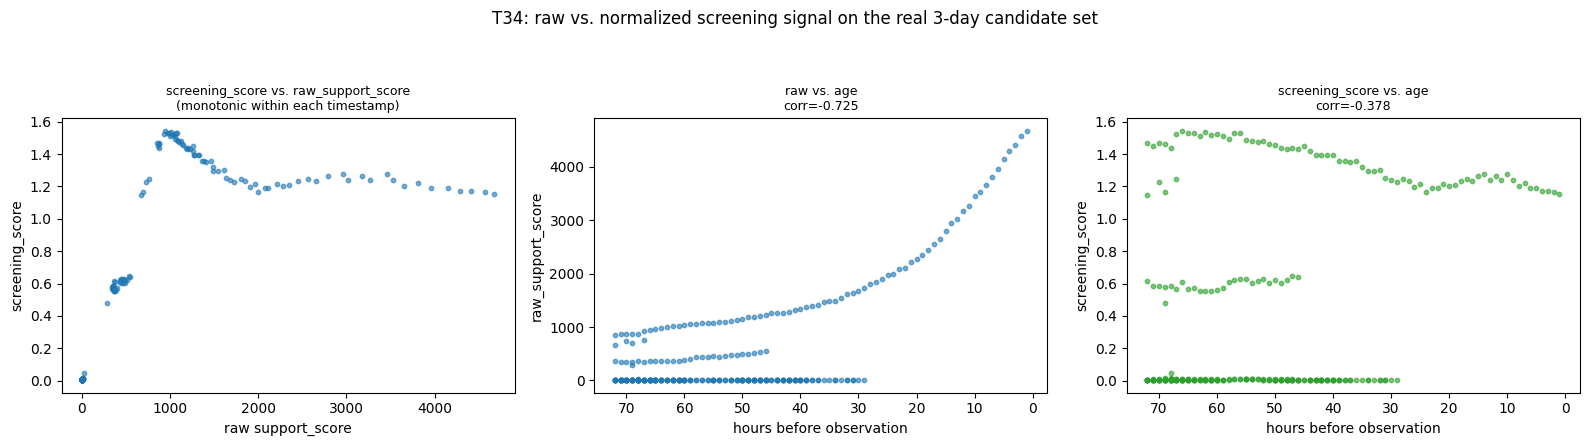

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].scatter(raw_vals, screening_vals, s=10, alpha=0.6)
axes[0].set_xlabel("raw support_score"); axes[0].set_ylabel("screening_score")
axes[0].set_title("screening_score vs. raw_support_score\n(monotonic within each timestamp)", fontsize=9)

axes[1].scatter(ages[valid_mask], raw_vals[valid_mask], s=10, alpha=0.6, color="tab:blue")
axes[1].set_xlabel("hours before observation"); axes[1].set_ylabel("raw_support_score")
axes[1].set_title(f"raw vs. age\ncorr={corr_raw_pearson:+.3f}", fontsize=9)
axes[1].invert_xaxis()

axes[2].scatter(ages[valid_mask], screening_vals[valid_mask], s=10, alpha=0.6, color="tab:green")
axes[2].set_xlabel("hours before observation"); axes[2].set_ylabel("screening_score")
axes[2].set_title(f"screening_score vs. age\ncorr={corr_screen_pearson:+.3f}", fontsize=9)
axes[2].invert_xaxis()

fig.suptitle("T34: raw vs. normalized screening signal on the real 3-day candidate set", fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.92))
fig.savefig(os.path.join(REPO_ROOT, "results", "actual_data", "T34_screening_normalization.png"), dpi=100)
plt.show()

## Known limitations (T34 scope only)

- `screening_score` is mathematically a thin derivative of T29's own per-timestamp
  normalization, NOT independent evidence -- T36 must treat `screening_score` and T29's
  normalized KDE as ONE evidence axis, not two (see `progress.md`'s T34 design spec).
- Not forced into `[0,1]`; kept in T29's own natural range as an explicit design choice.
- Any age correlation reported above is a diagnostic finding, not corrected for --
  consistent with the standing Phase 3 instruction applied to T29-T33.
- No Stage III module, and no existing T14-T17/T25/T26/T29 module, was modified.